In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ashery/chexpert")

print("Path to dataset files:", path)

c:\Users\ainav\Desktop\4 eng info\AI Vis\ChestVision\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\ainav\.cache\kagglehub\datasets\ashery\chexpert\versions\1


In [5]:
import urllib.request

import skimage
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms

import torchxrayvision as xrv

model_name = "densenet121-res224-all"

model = xrv.models.get_model(model_name)

In [7]:
from pathlib import Path
import os
import pandas as pd

root = Path(path)
def find_csv(name):
    candidates = sorted(root.rglob(name))
    if len(candidates) != 1:
        raise FileNotFoundError(f"Expected one {name} under {root}, found {len(candidates)}")
    return candidates[0]

train_csv = find_csv("train.csv")
valid_csv = find_csv("valid.csv")
df_train = pd.read_csv(train_csv)
df_valid = pd.read_csv(valid_csv)
print(df_train.columns.tolist())
print(df_valid.columns.tolist())



['Path', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices']
['Path', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices']


In [8]:
import numpy as np

#preprocessing the data

# merge train and valid first, everything else works on df
df_train["split"] = "train"
df_valid["split"] = "valid"
df = pd.concat([df_train, df_valid], ignore_index=True)


# I removed Lateral bc the model was performing unstably on them
df = df[df["Frontal/Lateral"] == "Frontal"].reset_index(drop=True)


def resolve_image_path(value):
    relative = Path(value)
    # Mirrors may retain or remove the CheXpert-v1.0-small directory.
    candidates = [root / relative, train_csv.parent / relative]
    if relative.parts and relative.parts[0] == "CheXpert-v1.0-small":
        candidates.extend([root / Path(*relative.parts[1:]),
                           train_csv.parent / Path(*relative.parts[1:])])
    for candidate in candidates:
        if candidate.is_file():
            return str(candidate)
    raise FileNotFoundError(f"Image from metadata not found: {value}")

df["full_path"] = df["Path"].map(resolve_image_path)
print(df["full_path"].iloc[0])

# chexpert uses 1 / 0 / -1 (uncertain) / blank, we treat -1 as unknown
label_cols = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Pleural Effusion",
              "Pneumonia", "Pneumothorax", "Lung Opacity", "Lung Lesion", "Fracture",
              "Enlarged Cardiomediastinum", "Support Devices", "No Finding"]

for c in label_cols:
    df[c] = df[c].fillna(0).replace(-1, np.nan)

df["age_bin"] = pd.cut(df["Age"], bins=[0, 40, 60, 75, 120], labels=["<40", "40-60", "60-75", "75+"])
df["view"] = np.where(df["Frontal/Lateral"] == "Lateral", "Lateral", df["AP/PA"].fillna("unknown"))
df["devices"] = df["Support Devices"].map({1.0: "yes", 0.0: "no"}).fillna("uncertain")

# full set is 220k images its too muuch
sub = pd.concat([
    df[df.split == "valid"],
    df[df.split == "train"].sample(5000, random_state=42),
]).reset_index(drop=True)
print(len(sub))
sub[["view", "Sex", "age_bin", "devices"]].value_counts().head(20)

C:\Users\ainav\.cache\kagglehub\datasets\ashery\chexpert\versions\1\train\patient00001\study1\view1_frontal.jpg
5202


view  Sex     age_bin  devices
AP    Male    40-60    yes        532
              60-75    yes        484
      Female  60-75    yes        364
              40-60    yes        333
              75+      no         306
      Male    60-75    no         302
              75+      yes        299
              40-60    no         297
              75+      no         267
      Female  75+      yes        222
      Male    <40      yes        211
      Female  60-75    no         198
              <40      yes        165
              40-60    no         162
PA    Male    40-60    no         138
AP    Male    <40      no         118
PA    Male    60-75    no         105
AP    Female  <40      no          87
PA    Female  40-60    no          78
      Male    75+      no          78
Name: count, dtype: int64

In [ ]:
import numpy as np
from tqdm.auto import tqdm

import skimage.io
from torch.utils.data import Dataset, DataLoader

#Run everything through the model

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device).eval()

transform = torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(), xrv.datasets.XRayResizer(224)])

class XrayDS(Dataset):
    def __init__(self, paths):
        self.paths = paths
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = skimage.io.imread(self.paths[i])
        img = xrv.datasets.normalize(img, 255)
        if img.ndim > 2:
            img = img.mean(2)
        img = transform(img[None, ...])
        return torch.from_numpy(img).float()

loader = DataLoader(XrayDS(sub["full_path"].tolist()), batch_size=8, num_workers=0)

outs = []
with torch.no_grad():
    for x in tqdm(loader, total=len(loader), desc="Prediciendo en CPU"):
        outs.append(model(x.to(device)).cpu().numpy())
preds = np.concatenate(outs)

pred_df = pd.DataFrame(preds, columns=["pred_" + p for p in model.pathologies])
results = pd.concat([sub, pred_df], axis=1)

print("Forma de preds:", preds.shape)
print("Filas de results:", len(results))

Prediciendo en CPU: 100%|██████████| 651/651 [05:21<00:00,  2.03it/s]

Forma de preds: (5202, 18)
Filas de results: 5202


In [5]:
import pandas as pd
results = pd.read_csv("results.csv")

Atelectasis

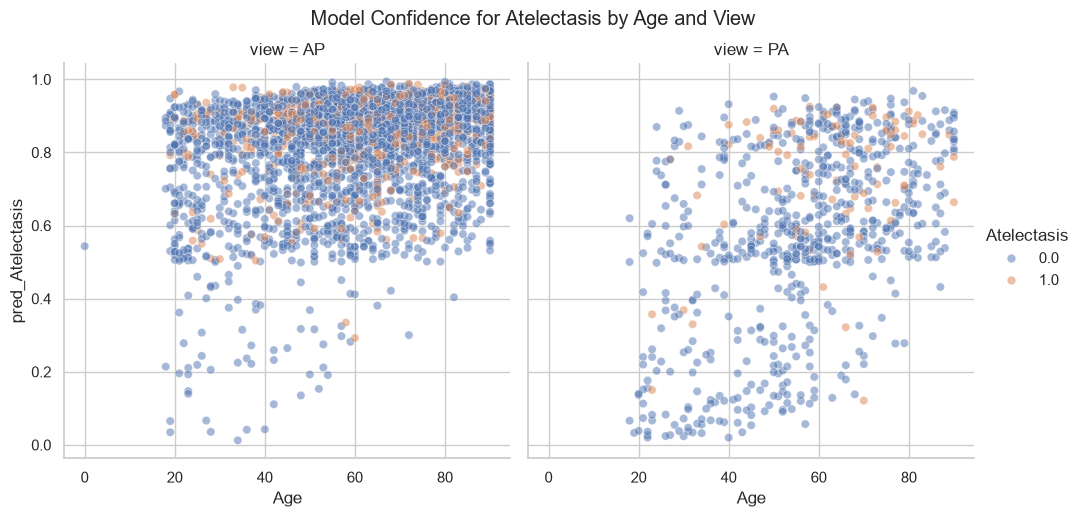

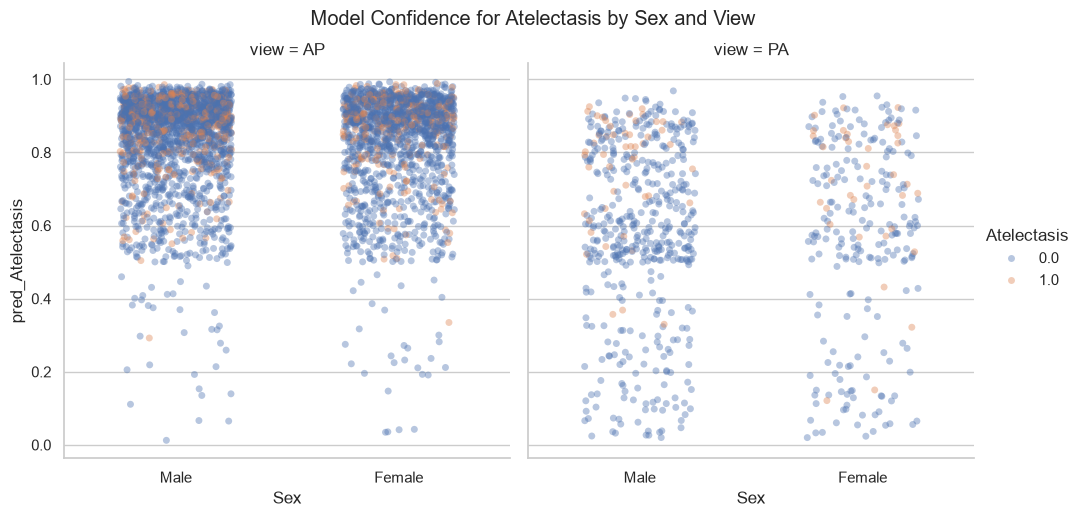

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

#scatter plot (views) by age
g1 = sns.relplot(data=results, x="Age", y="pred_Atelectasis", hue="Atelectasis", col="view", kind="scatter", alpha=0.5)
g1.fig.suptitle("Model Confidence for Atelectasis by Age and View", y=1.03)
plt.show()

#Model Confidence for Atelectasis by Sex
g2 = sns.catplot(
    data=results,
    x="Sex",
    y="pred_Atelectasis",
    hue="Atelectasis",
    col="view",
    kind="strip",
    jitter=0.25,
    alpha=0.4,
    height=5,
    aspect=1,
)
g2.fig.suptitle("Model Confidence for Atelectasis by Sex and View", y=1.03)

plt.show()

Consolidation

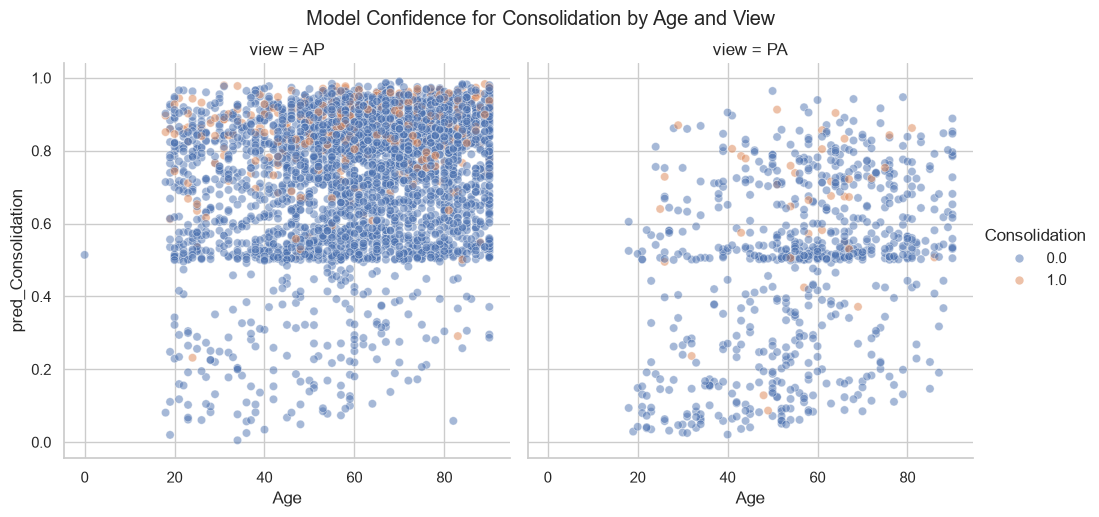

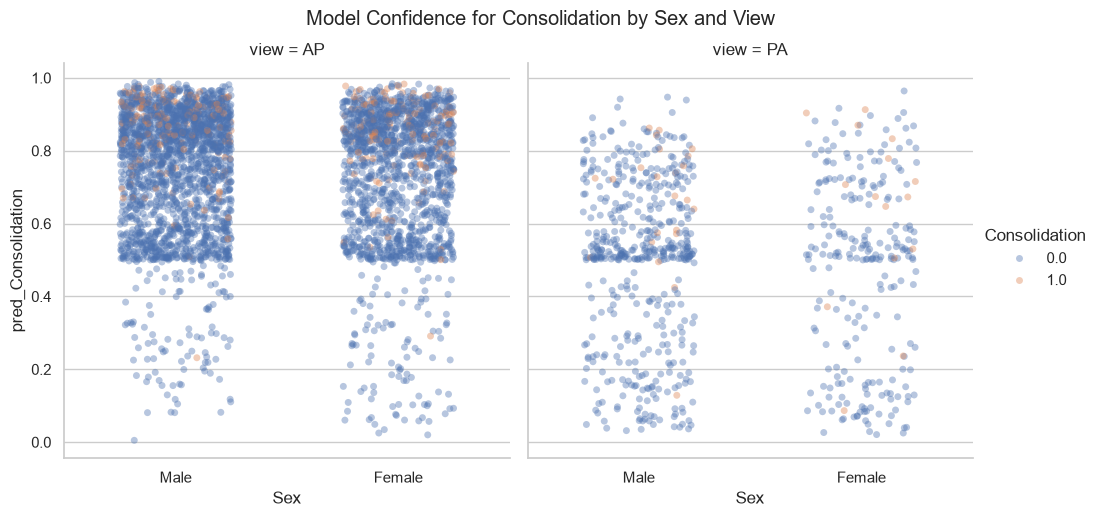

In [7]:

#scatter plot (views) by age
g1 = sns.relplot(data=results, x="Age", y="pred_Consolidation", hue="Consolidation", col="view", kind="scatter", alpha=0.5)
g1.fig.suptitle("Model Confidence for Consolidation by Age and View", y=1.03)
plt.show()

#Model Confidence for Consolidation by Sex
g2 = sns.catplot(
    data=results,
    x="Sex",
    y="pred_Consolidation",
    hue="Consolidation",
    col="view",
    kind="strip",
    jitter=0.25,
    alpha=0.4,
    height=5,
    aspect=1,
)
g2.fig.suptitle("Model Confidence for Consolidation by Sex and View", y=1.03)

plt.show()

Pneumothorax

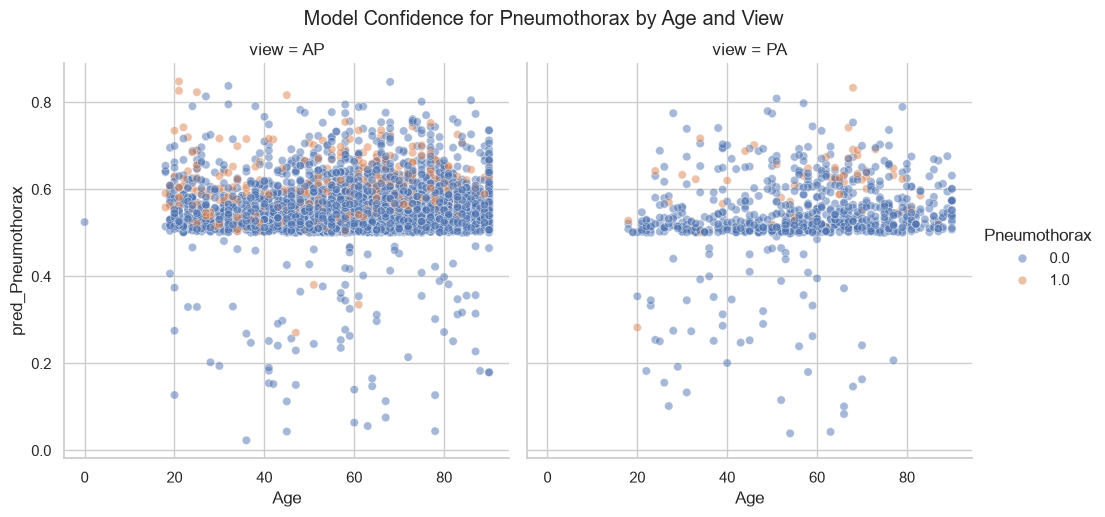

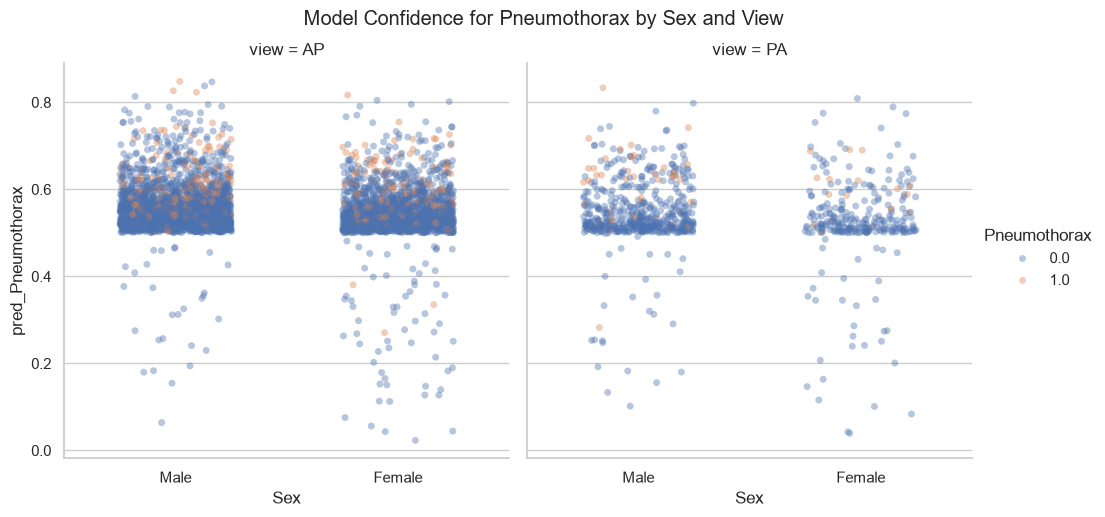

In [8]:

#scatter plot (views) by age
g1 = sns.relplot(data=results, x="Age", y="pred_Pneumothorax", hue="Pneumothorax", col="view", kind="scatter", alpha=0.5)
g1.fig.suptitle("Model Confidence for Pneumothorax by Age and View", y=1.03)

plt.show()

#Model Confidence for Pneumothorax by Sex
g2 = sns.catplot(
    data=results,
    x="Sex",
    y="pred_Pneumothorax",
    hue="Pneumothorax",
    col="view",
    kind="strip",
    jitter=0.25,
    alpha=0.4,
    height=5,
    aspect=1,
)
g2.fig.suptitle("Model Confidence for Pneumothorax by Sex and View", y=1.03)

plt.show()

Edema

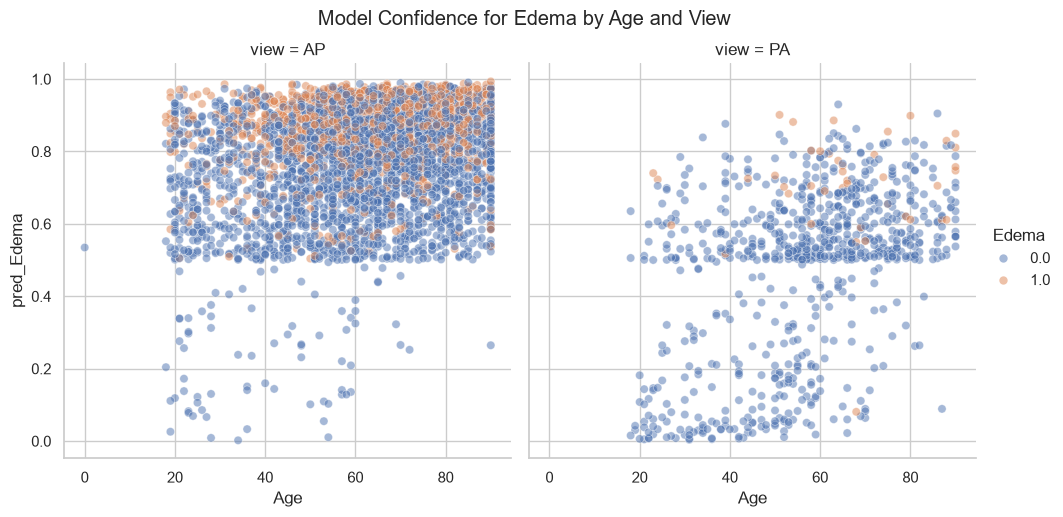

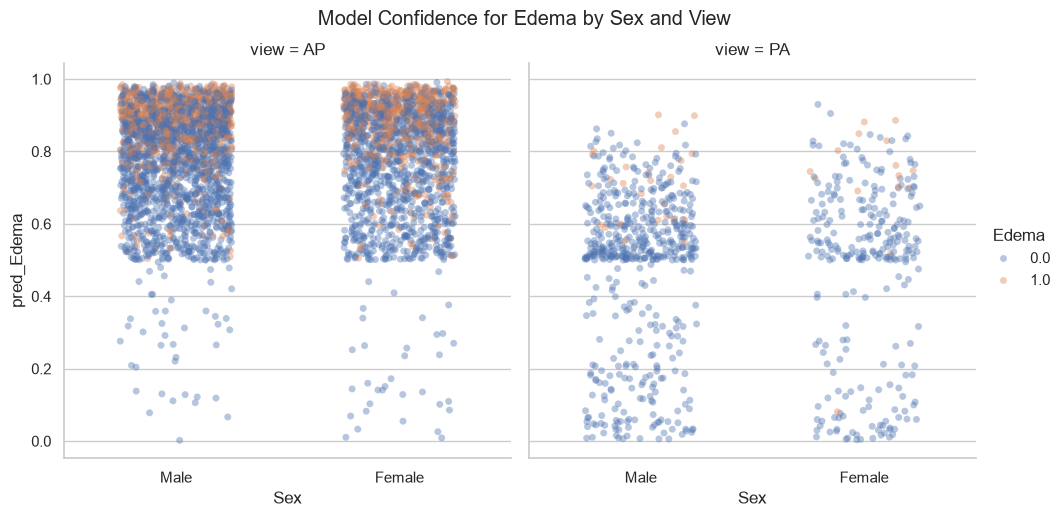

In [9]:

#scatter plot (views) by age
g1 = sns.relplot(data=results, x="Age", y="pred_Edema", hue="Edema", col="view", kind="scatter", alpha=0.5)
g1.fig.suptitle("Model Confidence for Edema by Age and View", y=1.03)

plt.show()

#Model Confidence for Edema by Sex
g2 =sns.catplot(
    data=results,
    x="Sex",
    y="pred_Edema",
    hue="Edema",
    col="view",
    kind="strip",
    jitter=0.25,
    alpha=0.4,
    height=5,
    aspect=1,
)
g2.fig.suptitle("Model Confidence for Edema by Sex and View", y=1.03)

plt.show()

Enlarged Cardiomediastinum

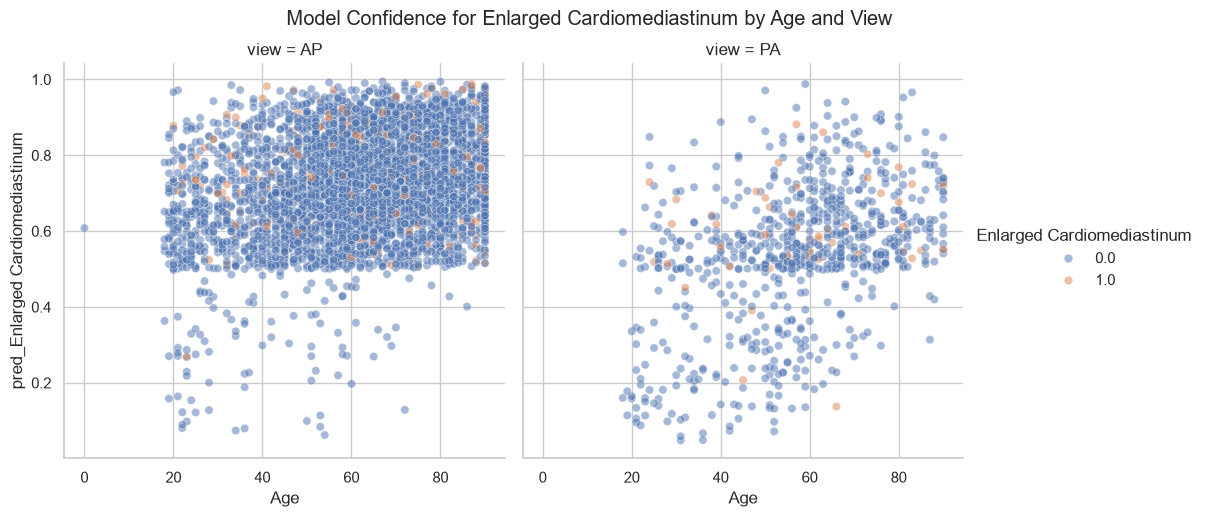

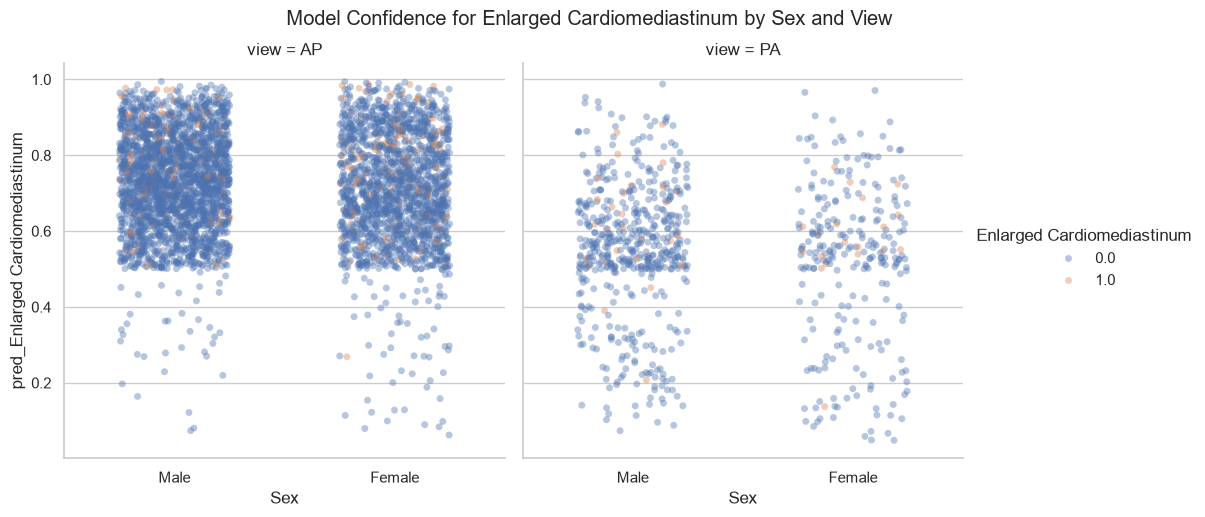

In [10]:

#scatter plot (views) by age
g1 = sns.relplot(data=results, x="Age", y="pred_Enlarged Cardiomediastinum", hue="Enlarged Cardiomediastinum", col="view", kind="scatter", alpha=0.5)
g1.fig.suptitle("Model Confidence for Enlarged Cardiomediastinum by Age and View", y=1.03)

plt.show()

#Model Confidence for Enlarged Cardiomediastinum by Sex
g2 = sns.catplot(
    data=results,
    x="Sex",
    y="pred_Enlarged Cardiomediastinum",
    hue="Enlarged Cardiomediastinum",
    col="view",
    kind="strip",
    jitter=0.25,
    alpha=0.4,
    height=5,
    aspect=1,
)
g2.fig.suptitle("Model Confidence for Enlarged Cardiomediastinum by Sex and View", y=1.03)

plt.show()

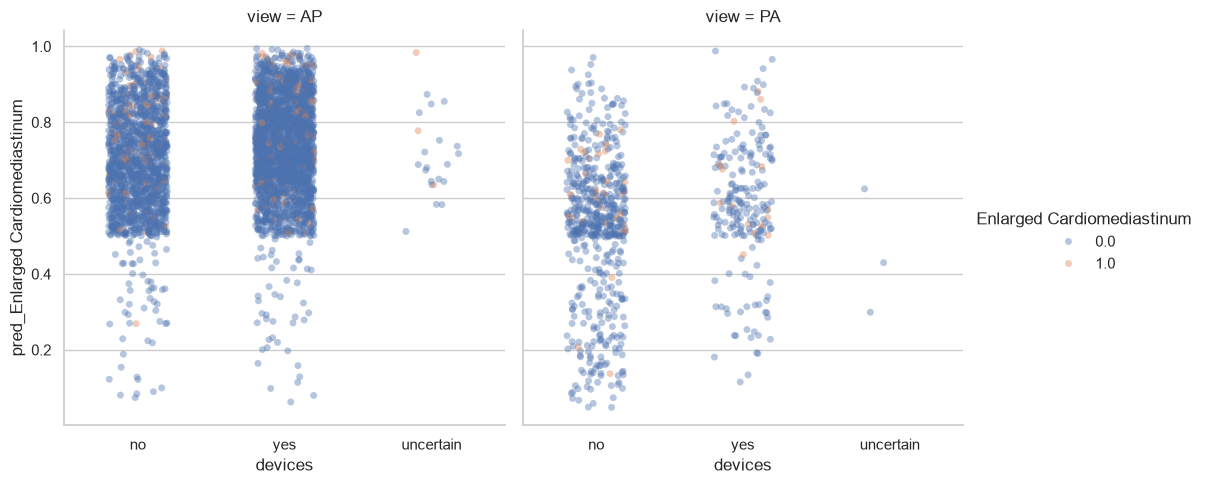

In [13]:
#large amount of false positives --> try to filter by devices 

sns.catplot(
    data=results,
    x="devices",
    y="pred_Enlarged Cardiomediastinum",
    hue="Enlarged Cardiomediastinum",
    col="view",
    kind="strip",
    jitter=0.2,
    alpha=0.4
)
plt.show()

Cardiomegaly

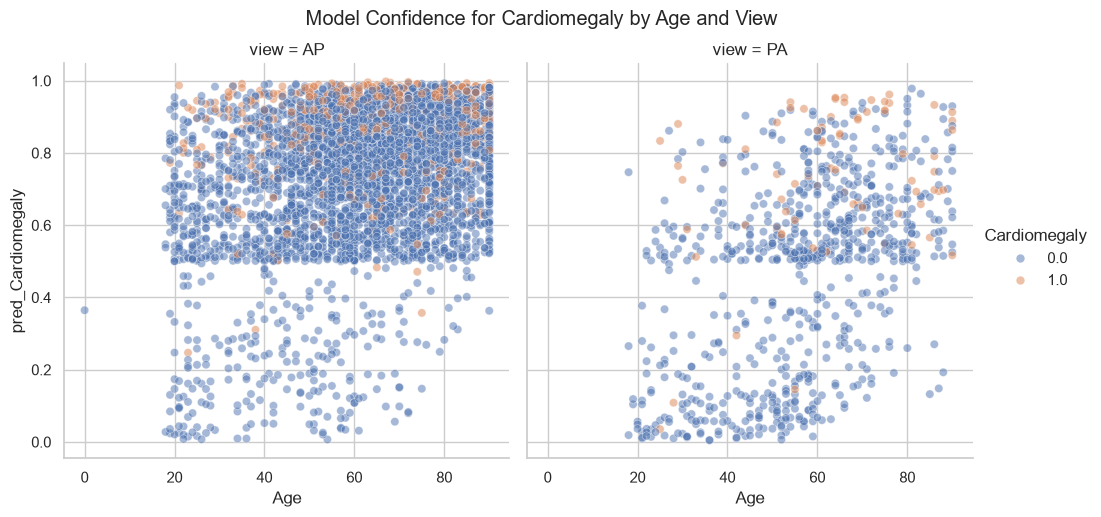

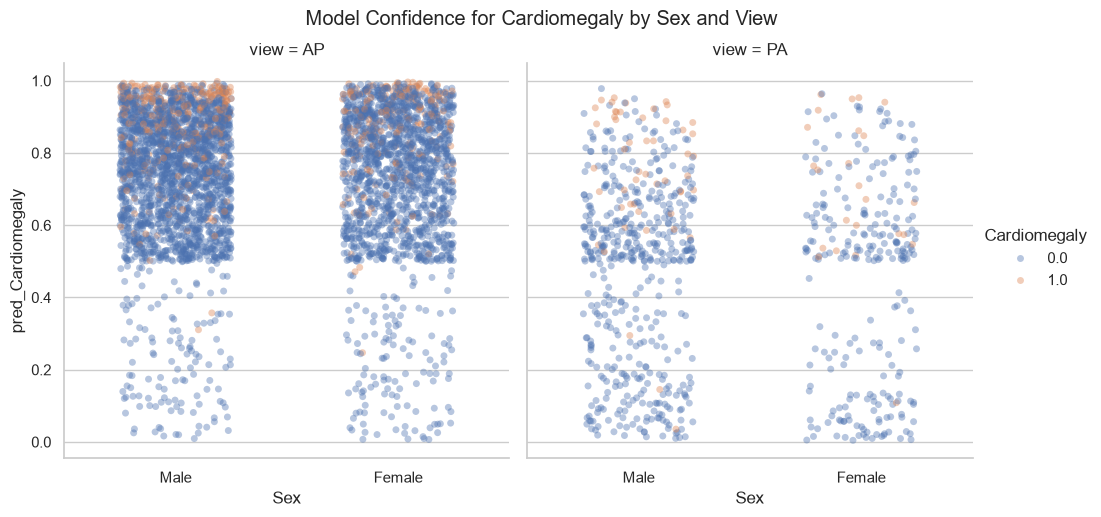

In [11]:

#scatter plot (views) by age
g1 = sns.relplot(data=results, x="Age", y="pred_Cardiomegaly", hue="Cardiomegaly", col="view", kind="scatter", alpha=0.5)
g1.fig.suptitle("Model Confidence for Cardiomegaly by Age and View", y=1.03)

plt.show()

#Model Confidence for Cardiomegaly by Sex
g2 = sns.catplot(
    data=results,
    x="Sex",
    y="pred_Cardiomegaly",
    hue="Cardiomegaly",
    col="view",
    kind="strip",
    jitter=0.25,
    alpha=0.4,
    height=5,
    aspect=1,
)
g2.fig.suptitle("Model Confidence for Cardiomegaly by Sex and View", y=1.03)

plt.show()

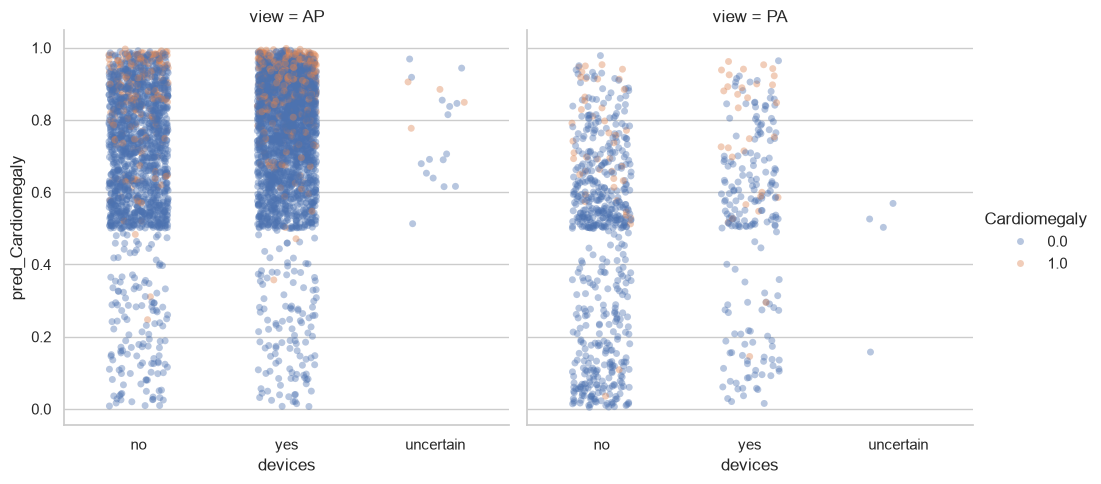

In [12]:
#large amount of false positives --> try to filter by devices 

sns.catplot(
    data=results,
    x="devices",
    y="pred_Cardiomegaly",
    hue="Cardiomegaly",
    col="view",
    kind="strip",
    jitter=0.2,
    alpha=0.4
)
plt.show()

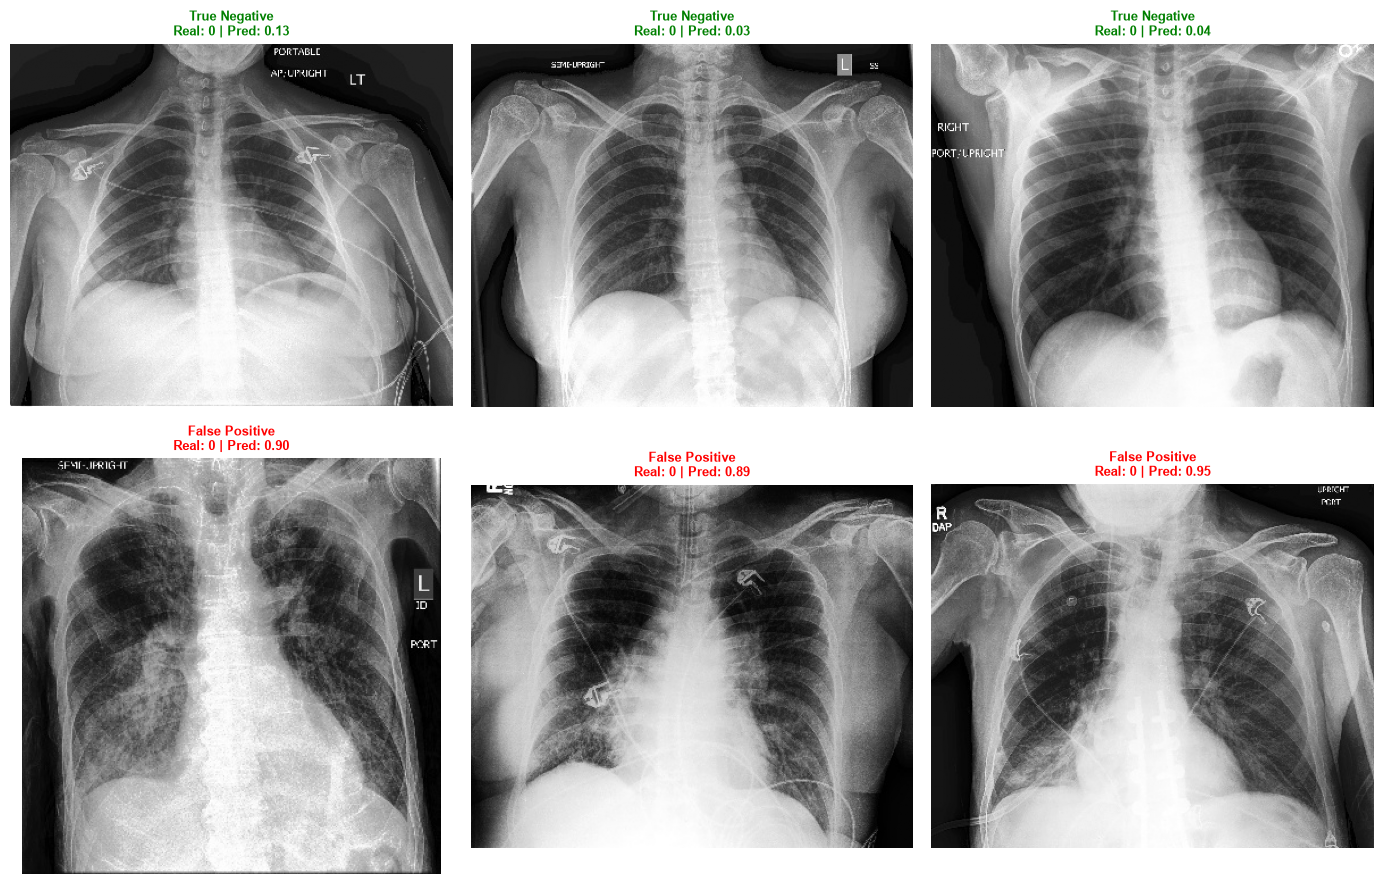

In [ ]:
#visualize the best and worse predictions of TN and FP
import skimage.io
#Correct predictions
tn_ap = results[(results["view"] == "AP") & (results["Cardiomegaly"] == 0.0) & (results["pred_Cardiomegaly"] < 0.15)].head(3)

#Incorrect predictions
fp_ap = results[(results["view"] == "AP") & (results["Cardiomegaly"] == 0.0) & (results["pred_Cardiomegaly"] > 0.85)].head(3)

comparison = pd.concat([tn_ap, fp_ap])

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, (_, row) in zip(axes.flat, comparison.iterrows()):
    img = skimage.io.imread(row["full_path"])
    ax.imshow(img, cmap="gray")
    
    real_val = int(row['Cardiomegaly'])
    pred_val = row['pred_Cardiomegaly']
    
    #classification
    if pred_val < 0.5:
        status = "True Negative"
        color = "green"
    else:
        status = "False Positive"
        color = "red"
        
    ax.set_title(f"{status}\nReal: {real_val} | Pred: {pred_val:.2f}", fontsize=9, color=color, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

Maybe devices affect when predicting a disease?
Confusion with other diaseases? or having other diaseases affects the prediction?

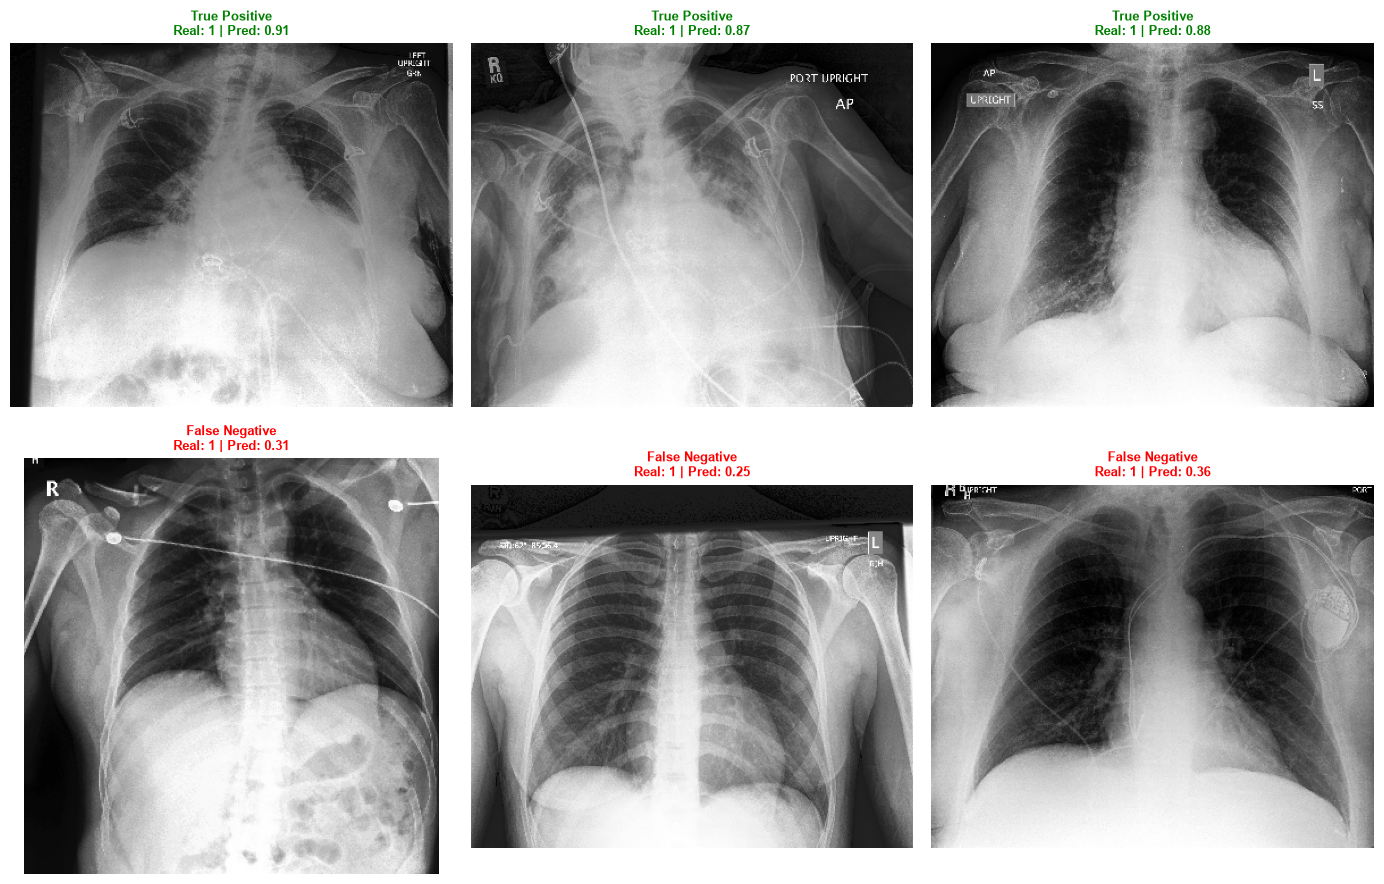

In [21]:
#visualize the best and worse predictions of TP and FN
import skimage.io
#Correct predictions
tp_ap = results[(results["view"] == "AP") & (results["Cardiomegaly"] == 1.0) & (results["pred_Cardiomegaly"] > 0.85)].head(3)

#Incorrect predictions
fn_ap = results[(results["view"] == "AP") & (results["Cardiomegaly"] == 1.0) & (results["pred_Cardiomegaly"] < 0.5)].head(3)

comparison = pd.concat([tp_ap, fn_ap])

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, (_, row) in zip(axes.flat, comparison.iterrows()):
    img = skimage.io.imread(row["full_path"])
    ax.imshow(img, cmap="gray")
    
    real_val = int(row['Cardiomegaly'])
    pred_val = row['pred_Cardiomegaly']
    
    #classification
    if pred_val < 0.5:
        status = "False Negative"
        color = "red"
    else:
        status = "True Positive"
        color = "green"
        
    ax.set_title(f"{status}\nReal: {real_val} | Pred: {pred_val:.2f}", fontsize=9, color=color, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

Left-bottom image has a pacemaker and is no reason for the model to predict positive. Clearer visualization of diaseses in TP images (bigger white shades). There are no big white shades in the FN ones.

Lung Opacity

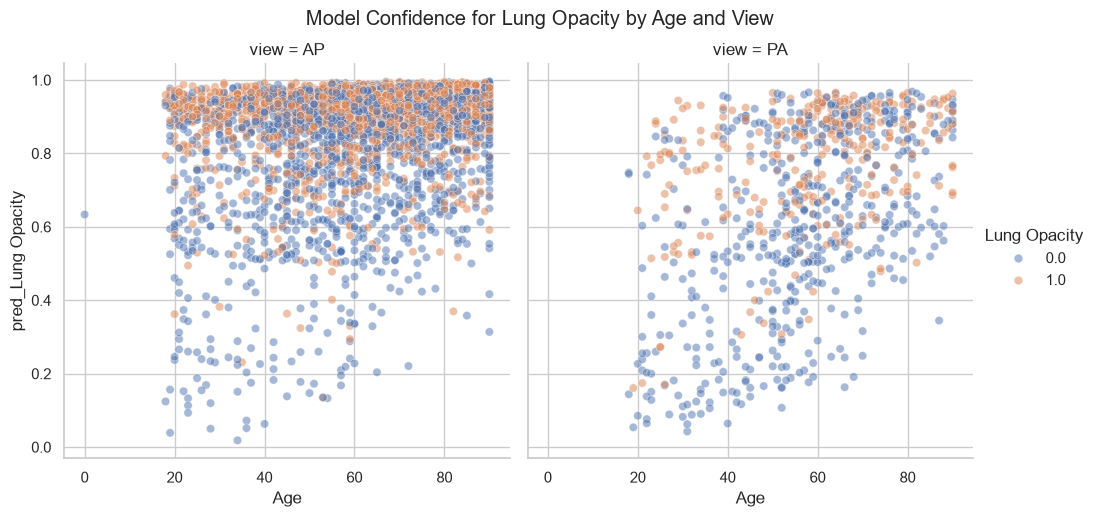

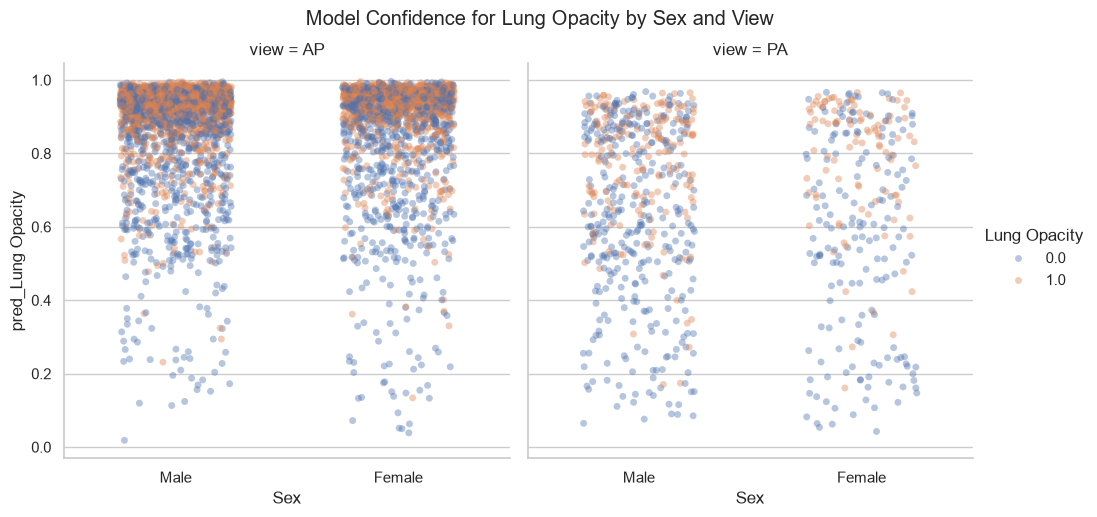

In [70]:

#scatter plot (views) by age
g1 = sns.relplot(data=results, x="Age", y="pred_Lung Opacity", hue="Lung Opacity", col="view", kind="scatter", alpha=0.5)
g1.fig.suptitle("Model Confidence for Lung Opacity by Age and View", y=1.03)

plt.show()

#Model Confidence for Lung Opacity by Sex
g2 = sns.catplot(
    data=results,
    x="Sex",
    y="pred_Lung Opacity",
    hue="Lung Opacity",
    col="view",
    kind="strip",
    jitter=0.25,
    alpha=0.4,
    height=5,
    aspect=1,
)
g2.fig.suptitle("Model Confidence for Lung Opacity by Sex and View", y=1.03)

plt.show()

Lung Lesion

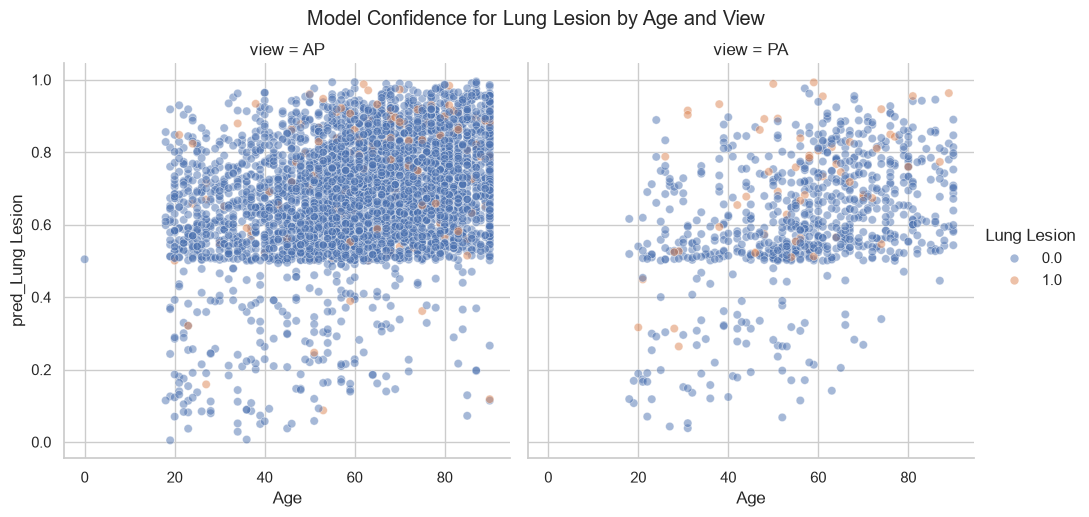

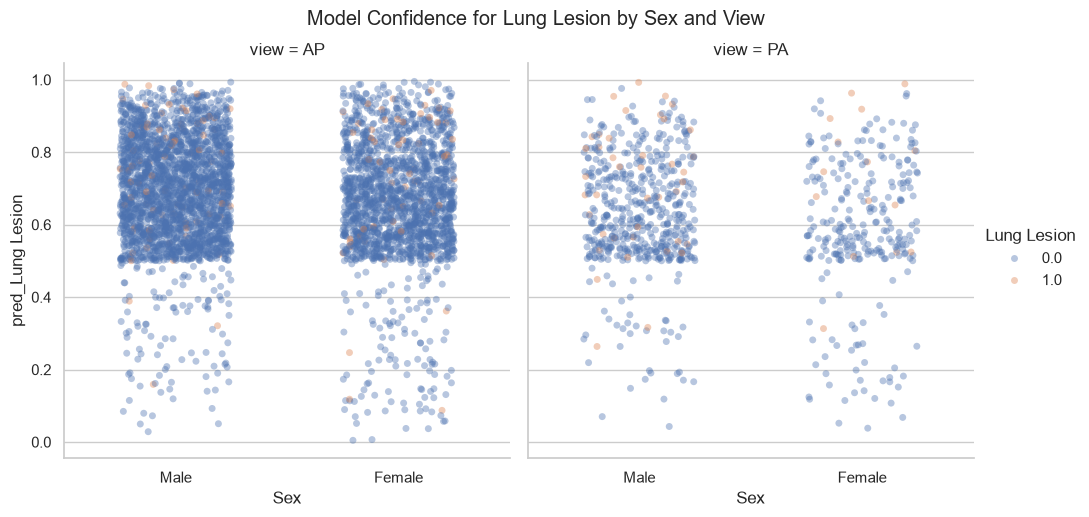

In [71]:

#scatter plot (views) by age
g1 = sns.relplot(data=results, x="Age", y="pred_Lung Lesion", hue="Lung Lesion", col="view", kind="scatter", alpha=0.5)
g1.fig.suptitle("Model Confidence for Lung Lesion by Age and View", y=1.03)

plt.show()

#Model Confidence for Lung Lesion by Sex
g2 = sns.catplot(
    data=results,
    x="Sex",
    y="pred_Lung Lesion",
    hue="Lung Lesion",
    col="view",
    kind="strip",
    jitter=0.25,
    alpha=0.4,
    height=5,
    aspect=1,
)
g2.fig.suptitle("Model Confidence for Lung Lesion by Sex and View", y=1.03)

plt.show()

Pneumonia

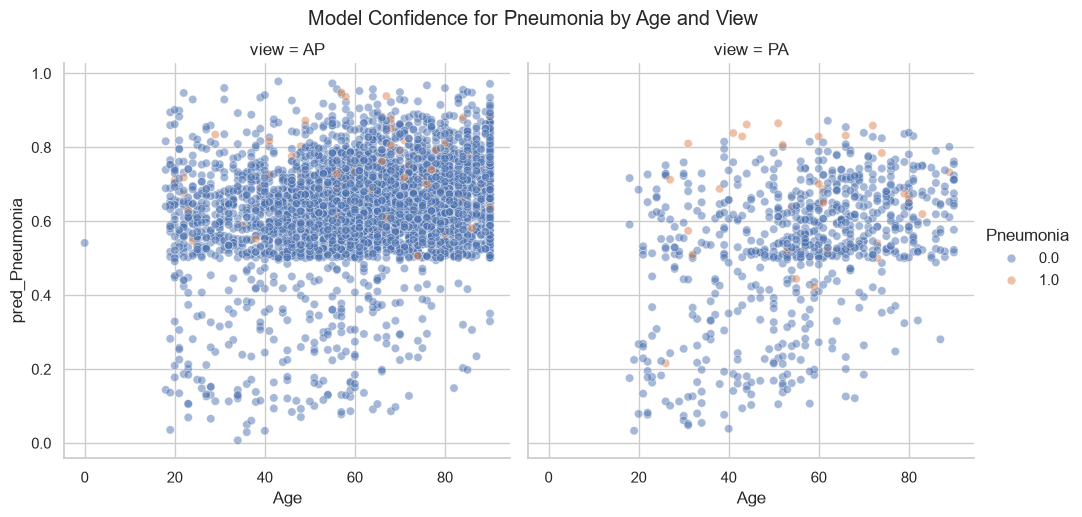

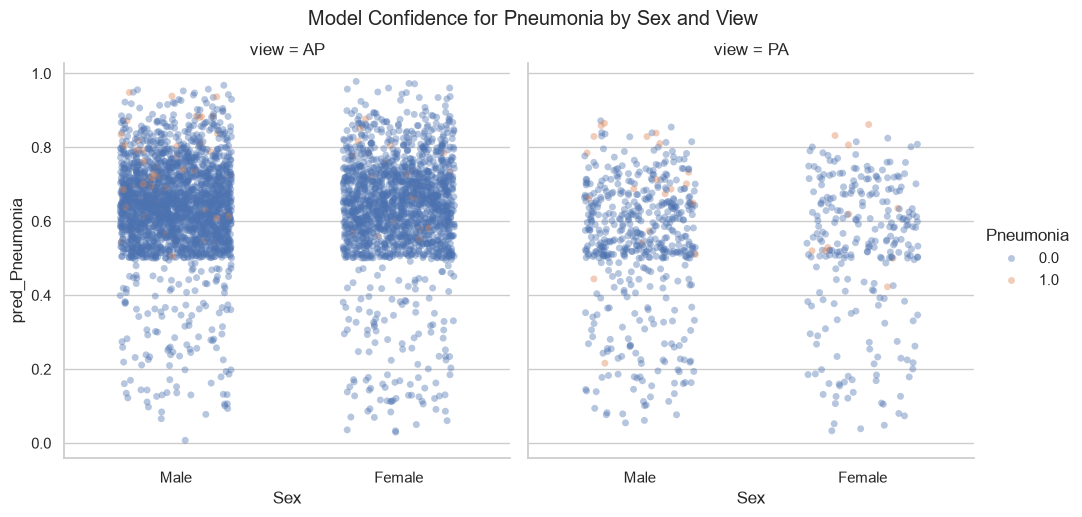

In [72]:

#scatter plot (views) by age
g1 = sns.relplot(data=results, x="Age", y="pred_Pneumonia", hue="Pneumonia", col="view", kind="scatter", alpha=0.5)
g1.fig.suptitle("Model Confidence for Pneumonia by Age and View", y=1.03)

plt.show()

#Model Confidence for Pneumonia by Sex
g2 = sns.catplot(
    data=results,
    x="Sex",
    y="pred_Pneumonia",
    hue="Pneumonia",
    col="view",
    kind="strip",
    jitter=0.25,
    alpha=0.4,
    height=5,
    aspect=1,
)
g2.fig.suptitle("Model Confidence for Pneumonia by Sex and View", y=1.03)

plt.show()

Fracture

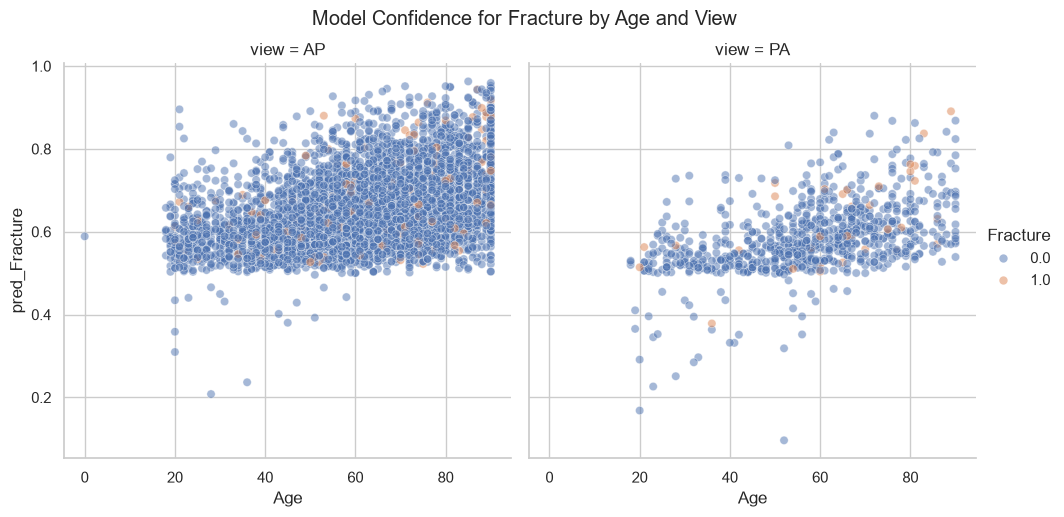

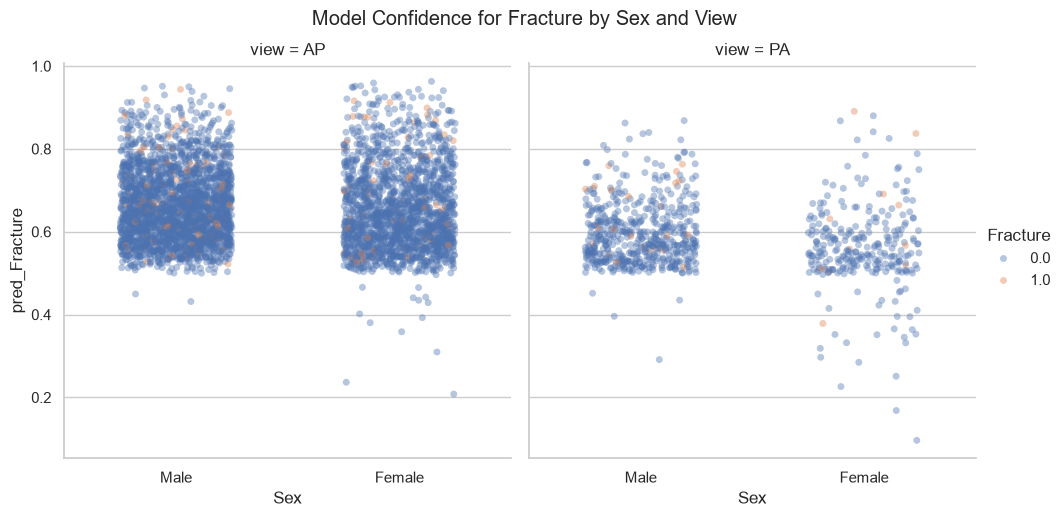

In [73]:

#scatter plot (views) by age
g1 = sns.relplot(data=results, x="Age", y="pred_Fracture", hue="Fracture", col="view", kind="scatter", alpha=0.5)
g1.fig.suptitle("Model Confidence for Fracture by Age and View", y=1.03)

plt.show()

#Model Confidence for Fracture by Sex
g2 = sns.catplot(
    data=results,
    x="Sex",
    y="pred_Fracture",
    hue="Fracture",
    col="view",
    kind="strip",
    jitter=0.25,
    alpha=0.4,
    height=5,
    aspect=1,
)
g2.fig.suptitle("Model Confidence for Fracture by Sex and View", y=1.03)

plt.show()